# Body Structure Exploratory Data Analysis

Analyze the structure and characteristics of GitHub issue bodies before designing text preprocessing and truncation strategies.

This analysis focuses on:

- Body length distributions across issue classes.
- Fenced code blocks and stack trace patterns.
- The proportion of text occupied by code blocks.
- Potential information loss caused by fixed-length truncation.
- Representative examples requiring manual inspection.

**Scope:** Training data only. No changes will be made to the original or processed datasets.

**Important:** Pattern detection is heuristic. The analysis is intended to inform future experiments, not establish final preprocessing rules.

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd().resolve().parent
sys.path.insert(0, str(ROOT))

In [2]:
import re

import numpy as np
import pandas as pd
import seaborn as sns

from src.data.sampling import load_stratified_sample

TRAIN_PATH = ROOT / "data/processed/train.csv"
SAMPLE_SIZE = 50_000
RANDOM_STATE = 42

sns.set_theme(style="whitegrid")
pd.set_option("display.max_colwidth", 180)

## 1. Dataset Sampling

A reproducible stratified sample of 50,000 training issues is selected for exploratory analysis.

Stratification preserves approximately the same class proportions as the training dataset.

Only `title`, `body`, and `labels` are loaded to reduce unnecessary memory usage.

The official test dataset remains untouched.

In [3]:
df = load_stratified_sample(
    csv_path=TRAIN_PATH,
    sample_size=SAMPLE_SIZE,
    random_state=RANDOM_STATE,
    columns=["title", "body", "labels"],
)

print("Dataset shape:", df.shape)
display(df["labels"].value_counts())
display(df.head())

Dataset shape: (50000, 3)


labels
bug              26525
feature          18198
question          3047
documentation     2230
Name: count, dtype: int64

,labels,title,body
0,bug,tests.unit.gapic.servicemanagement_v1.test_service_manager: test_list_services_pager failed,"This test failed!\n\nTo configure my behavior, see [the Flaky Bot documentation](https://github.com/googleapis/repo-automation-bots/tree/main/packages/flakybot).\n\nIf I'm comm..."
1,bug,[Bug]: the query result is not correct when the where filter has is null,### Is there an existing issue for the same bug?\n\n- [X] I have checked the existing issues.\n\n### Environment\n\n```markdown\n- Version or commit-id (e.g. v0.1.0 or 8b23a93)...
2,feature,Validation page updates,Request from Michael R: be clear those listed so far refer to package validation and not QC process\r\n\r\nAdd diffdf here which a programmer would use for QC.\r\n
3,bug,Query count not rendering (ppd-explorer),See issue #63 \r\nAlso missing in #64 \r\n\r\nQuery count is not rendering. Where results are capped at 100 or 1000 the string of text that displays total number of matching tr...
4,feature,How to remove the ‘square brackets’ for placeholders?,"\r\nHi, there. I am wondering is there a way to remove the square brackets used in this extension? \r\n\r\nWhen I want to edit the comments like ''[Type]'' and ''[description..."


## 2. Body Length Analysis

Issue bodies may vary significantly in length, ranging from short descriptions to extensive logs, code samples, and stack traces.

We examine the distribution of body lengths across classes using descriptive statistics and visualizations.

The 99th percentile is used as a visualization limit to prevent extreme outliers from dominating the plot. Original text values remain unchanged.

In [4]:
df["body_length"] = df["body"].str.len()

length_summary = df.groupby("labels")["body_length"].describe(
    percentiles=[0.5, 0.75, 0.9, 0.95, 0.99]
)

display(length_summary)

,count,mean,std,min,50%,75%,90%,95%,99%,max
labels,,,,,,,,,,
bug,26525.0,1678.791894,4827.254841,0.0,713.0,1477.0,3226.6,5539.6,16825.48,231386.0
documentation,2230.0,590.584753,1397.948425,0.0,304.0,616.0,1240.7,1843.6,4213.74,29062.0
feature,18198.0,616.264205,2064.239718,0.0,312.0,646.0,1206.0,1797.3,4246.03,135706.0
question,3047.0,1457.722678,4950.715466,0.0,590.0,1225.5,2879.2,4794.8,15259.16,210875.0


[Text(0.5, 1.0, 'Body Length Distribution (Clipped at P99)'),
 Text(0.5, 0, 'Body Length (Characters)'),
 Text(0, 0.5, 'Number of Issues')]

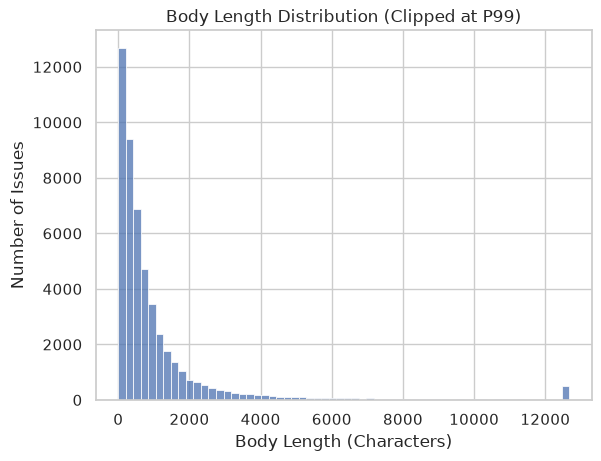

In [5]:
upper_limit = df["body_length"].quantile(0.99)

plot_data = df.assign(body_length_clipped=df["body_length"].clip(upper=upper_limit))

ax = sns.histplot(
    data=plot_data,
    x="body_length_clipped",
    bins=60,
)

ax.set(
    title="Body Length Distribution (Clipped at P99)",
    xlabel="Body Length (Characters)",
    ylabel="Number of Issues",
)

## 3. Code Blocks and Stack Traces

GitHub issue bodies frequently contain Markdown-formatted code snippets, error messages, and execution traces.

We use regular expressions to estimate the prevalence of:

- Fenced code blocks enclosed in triple backticks.
- Common Python traceback and Java-style stack trace patterns.

These patterns do not capture every possible code or traceback format. Their limitations will be considered during manual inspection.

In [6]:
FENCED_CODE_PATTERN = r"```[\s\S]*?```"
STACK_TRACE_PATTERN = (
    r"Traceback \(most recent call last\)"
    r"|^\s*at\s+[\w.$<>]+\("
    r'|^\s*File\s+"[^"]+",\s+line\s+\d+'
)

df["has_fenced_code"] = df["body"].str.contains(
    FENCED_CODE_PATTERN,
    regex=True,
)

df["has_stack_trace"] = df["body"].str.contains(
    STACK_TRACE_PATTERN,
    regex=True,
    flags=re.IGNORECASE | re.MULTILINE,
)

structure_summary = (
    df.groupby("labels")[["has_fenced_code", "has_stack_trace"]]
    .mean()
    .mul(100)
    .round(2)
)

display(structure_summary)

,has_fenced_code,has_stack_trace
labels,,
bug,32.67,5.60
documentation,11.17,0.40
feature,11.85,0.27
question,26.88,3.45


## 4. Code Block Character Ratio

Detecting the presence of code blocks is not sufficient to understand their impact on the available text.

We estimate the proportion of each issue body occupied by fenced code blocks.

A high code character ratio may motivate placeholder-based preprocessing, but it does not prove that code content is irrelevant to classification.

In [7]:
code_lengths = (
    df["body"]
    .str.findall(FENCED_CODE_PATTERN)
    .map(lambda blocks: sum(len(block) for block in blocks))
)

df["code_char_ratio"] = code_lengths.div(df["body_length"].replace(0, np.nan)).fillna(0)

display(df.groupby("labels")["code_char_ratio"].agg(["mean", "median", "max"]).round(3))

,mean,median,max
labels,,,
bug,0.180,0.0,1.0
documentation,0.048,0.0,1.0
feature,0.050,0.0,1.0
question,0.144,0.0,1.0


In [8]:
code_only_summary = (
    df.loc[df["has_fenced_code"]]
    .groupby("labels")["code_char_ratio"]
    .agg(["count", "mean", "median"])
    .round(3)
)

display(code_only_summary)

,count,mean,median
labels,,,
bug,8665,0.550,0.571
documentation,249,0.433,0.403
feature,2156,0.420,0.371
question,819,0.535,0.531


## 5. Truncation Risk Analysis

Fixed-length truncation can discard relevant information, particularly when code blocks or logs appear before the problem description.

We evaluate a hypothetical 1,000-character limit without modifying any text.

The analysis measures:

- The percentage of issues exceeding the limit.
- The average proportion of characters that would be removed.

These measurements describe text loss, not semantic information loss.

In [9]:
TRUNCATION_LIMIT = 1000

df["exceeds_limit"] = df["body_length"] > TRUNCATION_LIMIT

df["removed_char_ratio"] = (
    (df["body_length"] - TRUNCATION_LIMIT)
    .clip(lower=0)
    .div(df["body_length"].replace(0, np.nan))
    .fillna(0)
)

truncation_summary = df.groupby("labels").agg(
    pct_exceeds_limit=("exceeds_limit", "mean"),
    avg_removed_ratio=("removed_char_ratio", "mean"),
)

display((truncation_summary * 100).round(2))

,pct_exceeds_limit,avg_removed_ratio
labels,,
bug,37.55,17.94
documentation,13.14,5.22
feature,13.68,5.02
question,31.24,14.80


## 6. Manual Inspection

Quantitative measurements alone cannot determine whether truncation removes useful information.

We inspect long issues with a high proportion of fenced code blocks, comparing the first 1,000 characters against the text that follows.

The objective is to identify whether problem descriptions, expected behavior, reproduction steps, or other classification-relevant information appear after long code sections.

Representative findings will guide subsequent preprocessing experiments.

In [10]:
candidates = df.loc[
    (df["code_char_ratio"] > 0.5) & (df["body_length"] > 1000)
].sort_values(
    "code_char_ratio",
    ascending=False,
)

for _, row in candidates.head(5).iterrows():
    print("=" * 90)
    print("LABEL:", row["labels"])
    print("TITLE:", row["title"])
    print("BODY LENGTH:", row["body_length"])
    print("CODE RATIO:", round(row["code_char_ratio"], 3))
    print("\nFIRST 1000 CHARACTERS:\n")
    print(row["body"][:1000])
    print("\nREMAINING TEXT (FIRST 1500 CHARACTERS):\n")
    print(row["body"][1000:2500])

LABEL: bug
TITLE: wsock32.dll not copying
BODY LENGTH: 4546
CODE RATIO: 1.0

FIRST 1000 CHARACTERS:

```
Given server directory destination does exist.
Titanfall2 source exists
Server directory C:\Users\Austi\AppData\Local\NorthstarServer\1 does not exists. creating
C:\Users\Austi\AppData\Local\NorthstarServer\1\R2Northstar does not exist. copying
C:\Users\Austi\AppData\Local\NorthstarServer\1\legal.txt does not exist. copying
C:\Users\Austi\AppData\Local\NorthstarServer\1\MinHook.x64.dll does not exist. copying
C:\Users\Austi\AppData\Local\NorthstarServer\1\Northstar.dll does not exist. copying
C:\Users\Austi\AppData\Local\NorthstarServer\1\NorthstarLauncher.exe does not exist. copying
C:\Users\Austi\AppData\Local\NorthstarServer\1\ns_startup_args.txt does not exist. copying
C:\Users\Austi\AppData\Local\NorthstarServer\1\ns_startup_args_dedi.txt does not exist. copying
C:\Users\Austi\AppData\Local\NorthstarServer\1\r2ds.bat does not exist. copying
Warning! Titanfall2 sources R2Northst

## 7. Findings and Preprocessing Implications

**1. Body Length Distribution**

Issue body lengths exhibit a strongly right-skewed distribution, with substantial differences across classes.

- Bug reports have a median body length of 713 characters and a 99th percentile of approximately 16,825 characters.
- Questions have a median of 590 characters and a 99th percentile of approximately 15,259 characters.
- Feature requests and documentation issues generally have shorter bodies, with medians of 312 and 304 characters, respectively.
- Extreme outliers exist across multiple classes, suggesting that unrestricted text processing may introduce additional computational costs.

**2. Code Blocks and Stack Traces**

Fenced code blocks appear in approximately 32.67% of bug reports and 26.88% of questions, compared with 11.85% of feature requests and 11.17% of documentation issues.

Detected stack traces are also more common in bug reports (5.60%) and questions (3.45%).

These differences suggest that structural text features may contain class-relevant information. However, the current detection rules are heuristic and do not identify every code block, log, or stack trace format.

**3. Code Block Character Ratio**

Across all sampled issues, the average proportion of body characters occupied by detected fenced code blocks is:

- Bug: 18.0%
- Question: 14.4%
- Feature: 5.0%
- Documentation: 4.8%

When considering only issues containing detected fenced code blocks, the average ratios increase substantially:

| Class | Issues with Fenced Code | Mean Ratio | Median Ratio |
|---|---:|---:|---:|
| Bug | 8,665 | 55.0% | 57.1% |
| Documentation | 249 | 43.3% | 40.3% |
| Feature | 2,156 | 42.0% | 37.1% |
| Question | 819 | 53.5% | 53.1% |

These findings indicate that fenced blocks frequently occupy a substantial portion of issue bodies, particularly in bug reports and questions.

However, manual inspection revealed that fenced blocks may contain diagnostic logs, exception messages, and stack traces rather than source code alone.

Therefore, code block length should not be treated as a direct measure of irrelevant content. The impact of retaining, replacing, or selectively processing these blocks must be evaluated experimentally.

**4. Potential Truncation Impact**

A hypothetical 1,000-character body limit would truncate:

- 37.55% of bug reports.
- 31.24% of questions.
- 13.68% of feature requests.
- 13.14% of documentation issues.

The average proportion of characters removed across all issues is approximately 17.94% for bugs, 14.80% for questions, 5.02% for features, and 5.22% for documentation.

This indicates that fixed-length truncation would affect classes unevenly.

However, character removal is not equivalent to information loss, and its effect on classification performance remains untested.

**5. Manual Inspection**

Inspection of long, code-heavy bug reports revealed that fenced blocks frequently contain execution logs, exception messages, and stack traces rather than only source code.

Several examples contained potentially useful diagnostic information, such as exception types and error messages, beyond the first 1,000 characters.

Therefore, indiscriminate code block removal or replacement may discard classification-relevant information.

The manually inspected examples were deliberately selected from long, code-heavy issues and are not representative of the entire dataset.

### Preprocessing Implications

The findings motivate several controlled experiments:

1. **Raw full body:** Establish a reference model using title and unmodified body text.
2. **Code block replacement:** Evaluate whether replacing fenced blocks with placeholders improves generalization or reduces computational cost.
3. **Structured cleaning:** Explore selective Markdown, HTML, and log handling while preserving potentially informative error messages.
4. **Truncation:** Evaluate constrained input lengths independently, including their effects on minority-class performance.

Each strategy must be assessed using consistent training samples, validation data, model configurations, and evaluation metrics.

### Conclusion

The analysis does not justify applying a fixed 1,000-character truncation limit or indiscriminately removing fenced code blocks.

Body structure differs across issue classes, and manual inspection suggests that important diagnostic information may be embedded in lengthy code-formatted sections.

The next modeling step should establish a **Title + Raw Full Body** baseline before evaluating preprocessing or truncation strategies.

The official test dataset remains reserved for final evaluation.